<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/mae5911/MAE5911_Lista_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAE-5911 — Lista 2

**Aluna:** Jessica Matias Lewinter

In [1]:
# Algumas variáveis utilizadas globalmente
set.seed(5911) # Usado nos exercicios 1(d) e 2(e)
options(bitmapType = "cairo") # dispositivo PNG usado nas figuras do Jupyter

## Exercício 1 — $Z \sim \mathrm{Ber}(\theta)$, $\theta\in(0,1)$

> **Enunciado.** Seja $(Z_1,\dots,Z_n)$ uma amostra aleatória de $Z\sim\mathrm{Ber}(\theta)$,
> $\theta\in(0,1)$.
>
> (a) Encontre o EMV para $g(\theta)=P_\theta(Z=0)$.
>
> (b) Encontre o EMV para $g(\theta)=\mathrm{Var}_\theta(Z)$.
>
> (c) Considere que os dados foram observados $(0,0,1,0,0,1)$. Encontre as estimativas de MV nos
> itens acima.
>
> (d) Construa o valor-p para a hipótese $H$: "$\theta=0{,}1$" usando os dados do item anterior.
>
> *Justifique todos os passos.*

$f_\theta(x) = \theta^x(1-\theta)^{1-x}$, $x\in\{0,1\}$. Seja $S = \sum_{i=1}^n Z_i$. Então

$$L_{\mathbf z_n}(\theta) = \prod_{i=1}^n \theta^{z_i}(1-\theta)^{1-z_i} = \theta^{s}(1-\theta)^{n-s},
\qquad \ell(\theta) = s\ln\theta + (n-s)\ln(1-\theta).$$


Como $\ell'(\theta) = \dfrac{s}{\theta} - \dfrac{n-s}{1-\theta} = 0 \iff s(1-\theta) = (n-s)\theta
\iff \theta = s/n = \bar z_n.$
Como $\ell''(\theta) = -s/\theta^2 - (n-s)/(1-\theta)^2 < 0$ para todo $\theta\in(0,1)$ (quando
$0<s<n$), $\ell$ é estritamente côncava e $\bar z_n$ é o único máximo. Logo
$\hat\theta_{MV}(\mathbf Z_n) = \bar Z_n$.

**(a)Encontre o EMV para $g(\theta)=P_\theta(Z=0)$.**<br>
$g(\theta) = P_\theta(Z=0) = f_\theta(0) = 1-\theta$. Pela propriedade de invariância, o EMV de $g(\theta)$ é $g(\hat\theta_{MV}) = 1-\bar Z_n$.

**(b)Encontre o EMV para $g(\theta)=\mathrm{Var}_\theta(Z)$.**<br>
Como $Z^2 = Z$, $\mathrm{Var}_\theta(Z) = E_\theta(Z^2) - E_\theta(Z)^2 = \theta-\theta^2 =
\theta(1-\theta)$. Pela invariância, o EMV é $\bar Z_n(1-\bar Z_n)$.

**(c)Considere que os dados foram observados $(0,0,1,0,0,1)$. Encontre as estimativas de MV
nos itens acima.**<br>
Os dados observados $\langle 0,0,1,0,0,1\rangle$: $n=6$, $s=2$, $\bar z_n = 1/3$. As estimativas de MV são calculadas abaixo.

In [2]:
## ---- Exercício 1 (c): estimativas de MV ----
z1 <- c(0, 0, 1, 0, 0, 1)
n1 <- length(z1)
s1 <- sum(z1)
theta1.hat <- mean(z1)                       # EMV de theta
g1a.hat    <- 1 - theta1.hat                 # EMV de P(Z = 0) = 1 - theta
g1b.hat    <- theta1.hat * (1 - theta1.hat)  # EMV de Var(Z) = theta (1 - theta)

cat(sprintf("n = %d, s = sum(z) = %d, zbar = %.6f\n", n1, s1, theta1.hat))
cat(sprintf("EMV de theta           : %.6f\n", theta1.hat))
cat(sprintf("(a) EMV de P(Z=0)=1-theta: %.6f  (= 2/3)\n", g1a.hat))
cat(sprintf("(b) EMV de Var(Z)        : %.6f  (= 2/9)\n", g1b.hat))

n = 6, s = sum(z) = 2, zbar = 0.333333
EMV de theta           : 0.333333
(a) EMV de P(Z=0)=1-theta: 0.666667  (= 2/3)
(b) EMV de Var(Z)        : 0.222222  (= 2/9)


### (d) *Construa o valor-p para a hipótese $H$: "$\theta=0{,}1$" usando os dados do item anterior.*

Aqui $\Theta_0=\{0{,}1\}$, e $H_0$ inclui implicitamente as suposições de independência e de mesma
distribuição da amostra. Adaptando ao modelo Bernoulli as estatísticas do exemplo Poisson, todas não negativas e crescentes com a discrepância entre $\bar Z_n$ e $\theta_0=0{,}1$:

* Como $\sup_{\theta\in\Theta_0} L = L(\theta_0)$ e
  $\sup_{\theta\in\Theta} L = L(\bar Z_n)$,
  $$T_{H_0,RV}(\mathbf Z_n) = -2\ln\frac{L_{\mathbf Z_n}(\theta_0)}{L_{\mathbf Z_n}(\bar Z_n)}
  = 2\left[S\ln\frac{\bar Z_n}{\theta_0} + (n-S)\ln\frac{1-\bar Z_n}{1-\theta_0}\right],$$
  com a convenção $0\ln 0 = 0$.
* $\Lambda_\theta = -E_\theta[\partial^2\ln f_\theta(Z)/\partial\theta^2]
  = \theta/\theta^2 + (1-\theta)/(1-\theta)^2 = 1/(\theta(1-\theta))$, logo
  $V_\theta = \theta(1-\theta)$ e, avaliando em $\hat\theta_n=\bar Z_n$ como no livro,
  $T_{H_0,W}(\mathbf Z_n) = n(\bar Z_n-\theta_0)^2/[\bar Z_n(1-\bar Z_n)]$.
* $T_{H_0,S}(\mathbf Z_n) = n(\bar Z_n-\theta_0)^2/S^2_{n-1}$.
  Para dados 0/1, $S^2_{n-1} = \frac{n}{n-1}\bar Z_n(1-\bar Z_n)$, portanto
  $T_{H_0,S} = \frac{n-1}{n}T_{H_0,W}$.
* ** Variância avaliada em $\theta_0$:
  $T_{H_0,W_0}(\mathbf Z_n) = n(\bar Z_n-\theta_0)^2/[\theta_0(1-\theta_0)]$.

Sob $H_0$, todas convergem em distribuição para $\chi^2_1$, o que fornece o **valor-p assintótico** $\text{valor-p}^{(a)} = P(\chi^2_1 \ge T(\mathbf z_n))$
<br>

Para calcular o Valor-p exato, como $\Theta_0$ é unitário, o supremo é trivial, pois:

$\text{valor-p}(H_0,\mathbf z_n) = P^{(6)}_{0{,}1}\big(T(\mathbf Z_n)\ge T(\mathbf z_n)\big)$.
Cada estatística depende de $\mathbf Z_n$ apenas por meio de $S$, e sob $H_0$ tem-se
$S\sim\mathrm{Bin}(6,\,0{,}1)$. Basta então enumerar $s=0,\dots,6$:
$$\text{valor-p} = \sum_{s\,:\,T(s)\ge T(2)} \binom{6}{s}\,0{,}1^{s}\,0{,}9^{\,6-s}.$$
Com $n=6$ a aproximação $\chi^2_1$ não é confiável, de modo que o valor exato é a resposta principal.

In [3]:
## ---- Exercício 1 (d): valor-p para H0: theta = 0.1 ----
theta0 <- 0.1
xlogx  <- function(x) ifelse(x == 0, 0, x * log(x))   # convenção 0 log 0 = 0

# Estatísticas como funções de s = sum(z)
T.RV <- function(s, n, th0) 2 * (xlogx(s) + xlogx(n - s) - n * log(n) -
                                 s * log(th0) - (n - s) * log(1 - th0))
T.W  <- function(s, n, th0) { zb <- s / n; n * (zb - th0)^2 / (zb * (1 - zb)) }
T.S  <- function(s, n, th0) (n - 1) / n * T.W(s, n, th0)
T.W0 <- function(s, n, th0) { zb <- s / n; n * (zb - th0)^2 / (th0 * (1 - th0)) }

estat <- list(RV = T.RV, W = T.W, S = T.S, W0 = T.W0)

# valor-p exato: P_{theta0}(T(S) >= T(s_obs)), S ~ Bin(n, theta0)
valorp.exato <- function(Tfun, s.obs, n, th0) {
  s.todos <- 0:n
  T.todos <- Tfun(s.todos, n, th0)   # T.W(0) = T.W(n) = Inf
  sum(dbinom(s.todos, n, th0)[T.todos >= Tfun(s.obs, n, th0)])
}

tab1 <- t(sapply(estat, function(Tfun) {
  Tobs <- Tfun(s1, n1, theta0)
  c(T.obs = Tobs,
    valorp.assintotico = 1 - pchisq(Tobs, df = 1),
    valorp.exato = valorp.exato(Tfun, s1, n1, theta0))
}))
rownames(tab1) <- c("Razão de verossimilhanças (RV)",
                    "Variância em theta.hat (W)",
                    "Variância amostral S^2_{n-1} (S)",
                    "Variância em theta0")
print(round(tab1, 6))

cat("\nDistribuição de S ~ Bin(6, 0.1) sob H0 e estatísticas em s = 0..6:\n")
s.grid <- 0:n1
print(round(cbind(s = s.grid, P.H0 = dbinom(s.grid, n1, theta0),
                  T.RV = T.RV(s.grid, n1, theta0), T.W = T.W(s.grid, n1, theta0),
                  T.W0 = T.W0(s.grid, n1, theta0)), 5))
cat(sprintf("\nP_{0.1}(S >= 2) = %.6f\n", 1 - pbinom(1, n1, theta0)))

                                        T.obs valorp.assintotico valorp.exato
Razão de verossimilhanças (RV)       2.415054           0.120174     0.114265
Wald, variância em theta.hat (W)     1.470000           0.225346     0.645706
Variância amostral S^2_{n-1} (S)     1.225000           0.268382     0.645706
Wald, variância em theta0 (W0, aula) 3.629630           0.056759     0.114265

Distribuição de S ~ Bin(6, 0.1) sob H0 e estatísticas em s = 0..6:
     s    P.H0     T.RV    T.W     T.W0
[1,] 0 0.53144  1.26433    Inf  0.66667
[2,] 1 0.35429  0.25204  0.192  0.29630
[3,] 2 0.09842  2.41505  1.470  3.62963
[4,] 3 0.01458  6.12991  3.840 10.66667
[5,] 4 0.00121 11.20395  8.670 21.40741
[6,] 5 0.00005 17.82984 23.232 35.85185
[7,] 6 0.00000 27.63102    Inf 54.00000

P_{0.1}(S >= 2) = 0.114265


**Leitura dos resultados.**

* Para $T_{H_0,RV}$ e $T_{H_0,W_0}$ o conjunto $\{s : T(s)\ge T(2)\}$ é $\{2,3,4,5,6\}$, de modo que
  o valor-p exato é $P_{0{,}1}(S\ge 2) = 1 - 0{,}9^6 - 6\cdot 0{,}1\cdot 0{,}9^5 \approx 0{,}114$.
  Há portanto evidência fraca contra $H_0$, sob o cenário mais favorável a $H_0$
  observar algo tão ou mais discrepante que $s=2$ acontece em cerca de 11% das repetições.
* Para $T_{H_0,W}$ e $T_{H_0,S}$, o ponto $s=0$ tem $\bar z_n(1-\bar z_n)=0$ e a estatística vale
  $+\infty$, entrando no conjunto $\{T(s)\ge T(2)\}$ e inflando o valor-p exato para ≈ 0,65.

Abaixo, tem a demonstração de Monte Carlo o comportamento do valor-p

Proporção de valores-p <= 0.05 sob H0 (deve ser <= 0.05):
RV assintótico       RV exato 
        0.0161         0.0161 


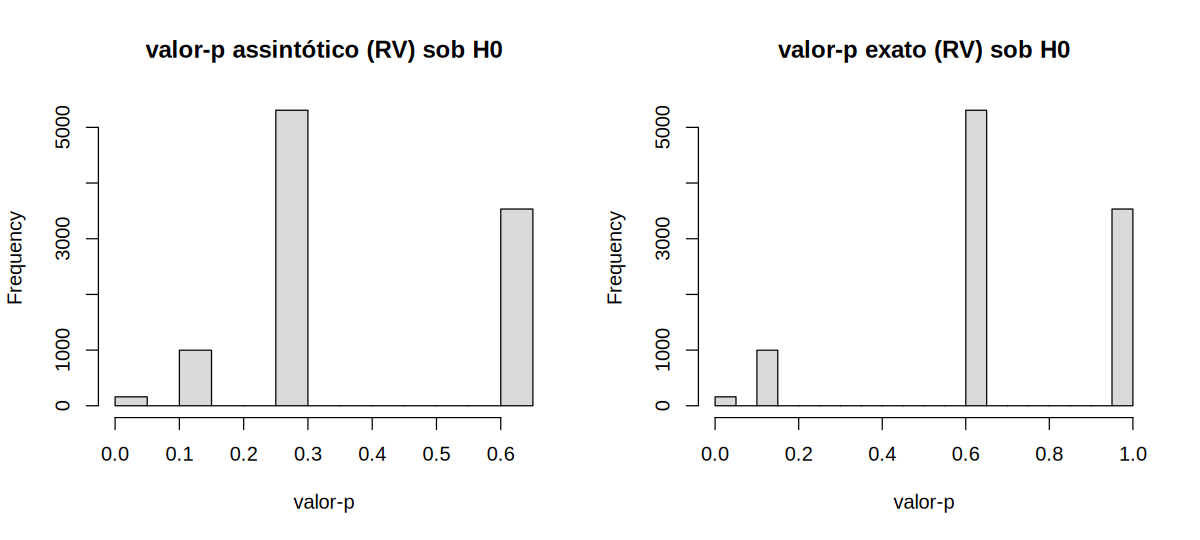

In [4]:
## ---- Exercício 1 (d): Monte Carlo do valor-p sob H0 ----
MC <- 10000
A1 <- matrix(0, MC, 2, dimnames = list(NULL, c("RV assintótico", "RV exato")))
for (i in 1:MC) {
  z <- rbinom(n1, size = 1, prob = theta0)
  s <- sum(z)
  A1[i, 1] <- 1 - pchisq(T.RV(s, n1, theta0), 1)
  A1[i, 2] <- valorp.exato(T.RV, s, n1, theta0)
}
options(repr.plot.width = 10, repr.plot.height = 4.5)
par(mfrow = c(1, 2))
hist(A1[, 1], main = "valor-p assintótico (RV) sob H0", xlab = "valor-p",
     col = "grey85")
hist(A1[, 2], main = "valor-p exato (RV) sob H0", xlab = "valor-p", col = "grey85")
cat("Proporção de valores-p <= 0.05 sob H0 (deve ser <= 0.05):\n")
print(colMeans(A1 <= 0.05))

**Leitura.** Como $S$ assume apenas sete valores, a distribuição do valor-p sob $H_0$ é discreta.
A proporção de valores-p abaixo de 5% é cerca de 1,6% para as duas versões, pois ambas rejeitam
exatamente quando $s\ge3$ e $P_{0{,}1}(S\ge3)\approx0{,}016$. Isso confirma a desigualdade
$P^{(n)}_\theta(\text{valor-p}\le\alpha)\le\alpha$. o valor-p é sub-uniforme sob $H_0$.
Note também que, para $s=0$, o valor-p assintótico ($\approx0{,}26$) é bem menor que o exato
($\approx0{,}65$).

## Exercício 2 — $Z\sim\mathrm{Exp}(\theta)$, $\theta\in(0,\infty)$

> **Enunciado.** Seja $(Z_1,\dots,Z_n)$ uma amostra aleatória de $Z\sim\mathrm{Exp}(\theta)$,
> $\theta\in(0,\infty)$.
>
> (a) Encontre o EMV para $g(\theta)=P_\theta(Z>1)$.
>
> (b) Encontre o EMV para $g(\theta)=P_\theta(0{,}1<Z<1)$.
>
> (c) Encontre o EMV para $g(\theta)=\mathrm{Var}_\theta(Z)$.
>
> (d) Considere que os dados foram observados $(0{,}2;\ 0{,}6;\ 0{,}3;\ 0{,}2;\ 0{,}8;\ 0{,}12)$.
> Encontre um IC aproximado de 95% de confiança para $g(\theta)$ nos itens acima.
>
> (e) Faça uma simulação de Monte Carlo para verificar se os IC's aproximados obtidos no passo
> anterior têm cobertura próxima do nível de confiança estabelecido. Caso não tenham, proponha um
> tamanho amostral que produza IC's aproximados mais confiáveis para cada caso.
>
> *Justifique todos os passos.*

$f_\theta(x) = \theta e^{-\theta x}$, $x>0$, em que $\theta^{-1}$ é a média
($E_\theta(Z)=1/\theta$, $\mathrm{Var}_\theta(Z)=1/\theta^2$).

$$L_{\mathbf z_n}(\theta) = \theta^n e^{-\theta\sum z_i},\qquad
\ell(\theta) = n\ln\theta - \theta\sum_{i=1}^n z_i,$$
$$\ell'(\theta) = \frac n\theta - \sum_{i=1}^n z_i = 0 \iff \theta = \frac{n}{\sum z_i} = \frac1{\bar z_n}.$$

$\ell''(\theta) = -n/\theta^2<0$ para todo $\theta>0$, logo $\hat\theta_{MV}(\mathbf Z_n) = 1/\bar Z_n$.

Por Fisher, temos $\ln f_\theta(x) = \ln\theta - \theta x$,
$\partial^2\ln f_\theta/\partial\theta^2 = -1/\theta^2$, logo $\Lambda_\theta = 1/\theta^2$ e
$V_\theta = \theta^2$, temos que $\sqrt n(\hat\theta_n-\theta)\xrightarrow{D}N(0,\theta^2)$.

**(a) Encontre o EMV para $g(\theta)=P_\theta(Z>1)$.**<br>
$g_a(\theta) = P_\theta(Z>1) = \int_1^\infty \theta e^{-\theta x}\,dx = e^{-\theta}$.
Pela invariância: $\hat g_a = e^{-1/\bar Z_n}$.

**(b) Encontre o EMV para $g(\theta)=P_\theta(0{,}1<Z<1)$.** <br>
 $g_b(\theta) = P_\theta(0{,}1<Z<1) = e^{-0{,}1\theta} - e^{-\theta}$.
Pela invariância: $\hat g_b = e^{-0{,}1/\bar Z_n} - e^{-1/\bar Z_n}$.

**(c) Encontre o EMV para $g(\theta)=\mathrm{Var}_\theta(Z)$.** <br>
$E_\theta(Z^2) = \int_0^\infty x^2\theta e^{-\theta x}dx = 2/\theta^2$, logo
$g_c(\theta) = \mathrm{Var}_\theta(Z) = 2/\theta^2 - 1/\theta^2 = 1/\theta^2$.
Pela invariância: $\hat g_c = \bar Z_n^{\,2}$.

In [5]:
## ---- Exercício 2: EMV e estimativas ----
z2 <- c(0.2, 0.6, 0.3, 0.2, 0.8, 0.12)
n2 <- length(z2)
zbar2 <- mean(z2)
theta2.hat <- 1 / zbar2

# g, g' e imagem de g para cada item (lista reutilizada nos itens d e e)
g2 <- list(
  a = list(nome = "P(Z > 1) = exp(-theta)",
           g  = function(th) exp(-th),
           dg = function(th) -exp(-th),
           inf = 0, sup = 1),
  b = list(nome = "P(0.1 < Z < 1) = exp(-0.1 theta) - exp(-theta)",
           g  = function(th) exp(-0.1 * th) - exp(-th),
           dg = function(th) -0.1 * exp(-0.1 * th) + exp(-th),
           inf = 0, sup = 1),
  c = list(nome = "Var(Z) = 1/theta^2",
           g  = function(th) 1 / th^2,
           dg = function(th) -2 / th^3,
           inf = 0, sup = Inf)
)

cat(sprintf("n = %d, soma = %.4f, zbar = %.6f\n", n2, sum(z2), zbar2))
cat(sprintf("EMV de theta (taxa): 1/zbar = %.6f\n\n", theta2.hat))
for (k in names(g2))
  cat(sprintf("(%s) EMV de %-45s : %.6f\n", k, g2[[k]]$nome, g2[[k]]$g(theta2.hat)))

n = 6, soma = 2.2200, zbar = 0.370000
EMV de theta (taxa): 1/zbar = 2.702703

(a) EMV de P(Z > 1) = exp(-theta)                        : 0.067024
(b) EMV de P(0.1 < Z < 1) = exp(-0.1 theta) - exp(-theta) : 0.696149
(c) EMV de Var(Z) = 1/theta^2                            : 0.136900


### (d) Intervalos de confiança aproximados de 95%

Temos que  $V_\theta=\theta^2$,
$\sqrt n\,(g(\hat\theta_n)-g(\theta))\xrightarrow{D}N\!\big(0,\,g'(\theta)^2\theta^2\big)$, e, por
Slutsky, podemos substituir $\theta$ por $\hat\theta_n$ na variância. Seguindo a cadeia de
igualdades do exemplo Poisson, com $\gamma=0{,}95$ e $q_{\gamma,1}$ o quantil 0,95 da
$\chi^2_1$ ($\sqrt{q_{\gamma,1}}=1{,}96$):

$$\begin{aligned}
C^{(g)}_\gamma(\mathbf Z_n)
&= \Big\{\theta\in\Theta : \frac{n\,(g(\hat\theta_n)-g(\theta))^2}{g'(\hat\theta_n)^2\,\hat\theta_n^2}\le q_{\gamma,1}\Big\}\\
&= \Big[\,g(\hat\theta_n) - 1{,}96\,|g'(\hat\theta_n)|\tfrac{\hat\theta_n}{\sqrt n},\;
       g(\hat\theta_n) + 1{,}96\,|g'(\hat\theta_n)|\tfrac{\hat\theta_n}{\sqrt n}\Big]\cap \mathrm{Im}(g).
\end{aligned}$$

Derivadas: $g_a'(\theta) = -e^{-\theta}$; $g_b'(\theta) = -0{,}1e^{-0{,}1\theta}+e^{-\theta}$;
$g_c'(\theta) = -2/\theta^3$.
As imagens são $(0,1)$ para as probabilidades e $(0,\infty)$ para a variância.

**Alternativa para $g$ monótona (a e c).** Do IC aproximado para $\theta$,
$C_\gamma(\mathbf Z_n) = [\hat\theta_n(1-1{,}96/\sqrt n),\ \hat\theta_n(1+1{,}96/\sqrt n)]\cap(0,\infty)$,
obtém-se $g(C_\gamma(\mathbf Z_n))$ com a **mesma** cobertura, pois os eventos
$\{\theta\in C_\gamma\}$ e $\{g(\theta)\in g(C_\gamma)\}$ coincidem quando $g$ é monótona. Para $g_c$
há ainda a versão em escala logarítmica, $\ln\hat\theta_n \pm 1{,}96/\sqrt n$ (pois
$V_{\ln\theta} = (1/\theta)^2\theta^2 = 1$), que não depende de $\theta$ e respeita a imagem de $g$.

In [6]:
## ---- Exercício 2 (d): IC aproximado para g(theta) ----
gama  <- 0.95
c.g   <- sqrt(qchisq(gama, 1))

ic.delta <- function(th.hat, n, item, c.g = sqrt(qchisq(0.95, 1))) {
  meia <- c.g * abs(item$dg(th.hat)) * th.hat / sqrt(n)   # sqrt(V/n) = th.hat/sqrt(n)
  c(inf = max(item$inf, item$g(th.hat) - meia),
    sup = min(item$sup, item$g(th.hat) + meia))
}

tab2d <- t(sapply(g2, function(item) {
  ic <- ic.delta(theta2.hat, n2, item, c.g)
  c(g.hat = item$g(theta2.hat), dg.hat = item$dg(theta2.hat),
    semiamplitude = c.g * abs(item$dg(theta2.hat)) * theta2.hat / sqrt(n2),
    IC.inf = ic[["inf"]], IC.sup = ic[["sup"]])
}))
cat(sprintf("sqrt(q_{0.95,1}) = %.6f;  sqrt(V/n) = theta.hat/sqrt(n) = %.6f\n\n",
            c.g, theta2.hat / sqrt(n2)))
print(round(tab2d, 6))

# IC para theta e transformação por g monótona
ic.theta <- theta2.hat * c(1 - c.g / sqrt(n2), 1 + c.g / sqrt(n2))
ic.theta <- pmax(ic.theta, 0)
cat(sprintf("\nIC aproximado para theta: [%.6f, %.6f]\n", ic.theta[1], ic.theta[2]))
cat(sprintf("(a) g_a(IC_theta), g_a decrescente : [%.6f, %.6f]\n",
            g2$a$g(ic.theta[2]), g2$a$g(ic.theta[1])))
sup.c <- if (ic.theta[1] > 0) sprintf("%.6f", g2$c$g(ic.theta[1])) else "Inf"
cat(sprintf("(c) g_c(IC_theta), g_c decrescente : [%.6f, %s]\n",
            g2$c$g(ic.theta[2]), sup.c))
ic.logtheta <- theta2.hat * exp(c(-1, 1) * c.g / sqrt(n2))
cat(sprintf("(c) via log(theta): IC_theta = [%.6f, %.6f]\n",
            ic.logtheta[1], ic.logtheta[2]))
cat(sprintf("                    IC Var    = [%.6f, %.6f]\n",
            1 / ic.logtheta[2]^2, 1 / ic.logtheta[1]^2))

sqrt(q_{0.95,1}) = 1.959964;  sqrt(V/n) = theta.hat/sqrt(n) = 1.103374

     g.hat    dg.hat semiamplitude   IC.inf   IC.sup
a 0.067024 -0.067024      0.144945 0.000000 0.211969
b 0.696149 -0.009293      0.020097 0.676052 0.716246
c 0.136900 -0.101306      0.219082 0.000000 0.355982

IC aproximado para theta: [0.540130, 4.865276]
(a) g_a(IC_theta), g_a decrescente : [0.007710, 0.582673]
(c) g_c(IC_theta), g_c decrescente : [0.042246, 3.427706]
(c) via log(theta): IC_theta = [1.214218, 6.015890]
                    IC Var    = [0.027631, 0.678276]


**Leitura.** Com $n=6$, $1{,}96/\sqrt 6\approx 0{,}80$: o IC para $\theta$ cobre quase uma ordem de
grandeza, e o IC delta de (a) bate na fronteira da imagem (limite inferior truncado em 0). O IC de
(b) é estreitíssimo pois ($g_b'(\hat\theta)\approx 0$).
Para (c), o IC delta $\bar z_n^2(1\pm 3{,}92/\sqrt n)$ tem limite inferior negativo sempre que
$n<16$, sendo truncado em 0.

### (e) Simulação de Monte Carlo
> Faça uma simulação de Monte Carlo para verificar se os IC's aproximados obtidos no passo anterior têm cobertura próxima do nível de confiança estabelecido. Caso não tenham, proponha um tamanho amostral que produza IC's aproximados mais confiáveis para cada caso.

Usamos $MC = 10\,000$ amostras de tamanho $n$ de
$\mathrm{Exp}(\theta)$, construímos o IC delta de cada item em cada amostra e registramos a frequência relativa de intervalos que contêm o verdadeiro $g(\theta)$. Fazemos isso para
$\theta\in\{\hat\theta_n\approx 2{,}70;\ 0{,}5;\ 5\}$ e
$n\in\{6,10,20,30,50,100,200,500,1000\}$. Para (c) o IC delta depende dos dados apenas por
$\theta\bar Z_n\sim\mathrm{Gama}(n,n)$, logo sua cobertura não depende de $\theta$; para (a) e (b)
depende. Comparamos também as alternativas do item (d): $g(C_\gamma(\theta))$ (que tem a cobertura do
IC de $\theta$) e a versão em escala log.

In [7]:
## ---- Exercício 2 (e): Monte Carlo ----
MC <- 10000
cobertura <- function(theta, n, MC = 10000, c.g = sqrt(qchisq(0.95, 1))) {
  Z  <- matrix(rexp(n * MC, rate = theta), nrow = MC, ncol = n)
  th <- 1 / rowMeans(Z)                                   # EMV
  cob <- sapply(g2, function(item) {                      # ICs de (a), (b), (c)
    meia   <- c.g * abs(item$dg(th)) * th / sqrt(n)
    g.true <- item$g(theta)
    mean(item$g(th) - meia <= g.true & g.true <= item$g(th) + meia)
  })
  r <- c.g / sqrt(n)
  cob.theta <- mean(th * (1 - r) <= theta & theta <= th * (1 + r))
  cob.log   <- mean(th * exp(-r) <= theta & theta <= th * exp(r))
  c(cob, "IC de theta" = cob.theta, "IC via log(theta)" = cob.log)
}

ns     <- c(6, 10, 20, 30, 50, 100, 200, 500, 1000)
thetas <- c(theta2.hat, 0.5, 5)
res2e  <- lapply(thetas, function(th) {
  m <- t(sapply(ns, function(n) cobertura(th, n, MC, c.g)))
  rownames(m) <- paste0("n=", ns)
  m
})
names(res2e) <- sprintf("theta = %.4f", thetas)

for (k in seq_along(res2e)) {
  cat(sprintf("\nCobertura empírica (MC = %d), %s:\n", MC, names(res2e)[k]))
  print(round(res2e[[k]], 4))
}


Cobertura empírica (MC = 10000), theta = 2.7027:
            a      b      c IC de theta (= g monótona) IC via log(theta)
n=6    0.7997 0.9862 0.8266                     0.9546            0.9374
n=10   0.8416 0.9886 0.8601                     0.9554            0.9381
n=20   0.8862 0.9854 0.8976                     0.9544            0.9454
n=30   0.9078 0.9798 0.9171                     0.9527            0.9513
n=50   0.9176 0.9702 0.9245                     0.9530            0.9476
n=100  0.9347 0.9475 0.9397                     0.9510            0.9491
n=200  0.9436 0.9125 0.9453                     0.9522            0.9506
n=500  0.9469 0.8639 0.9483                     0.9521            0.9517
n=1000 0.9492 0.8674 0.9497                     0.9522            0.9514

Cobertura empírica (MC = 10000), theta = 0.5000:
            a      b      c IC de theta (= g monótona) IC via log(theta)
n=6    0.9180 0.9060 0.8162                     0.9604            0.9306
n=10   0.9315 0.9256 0.8

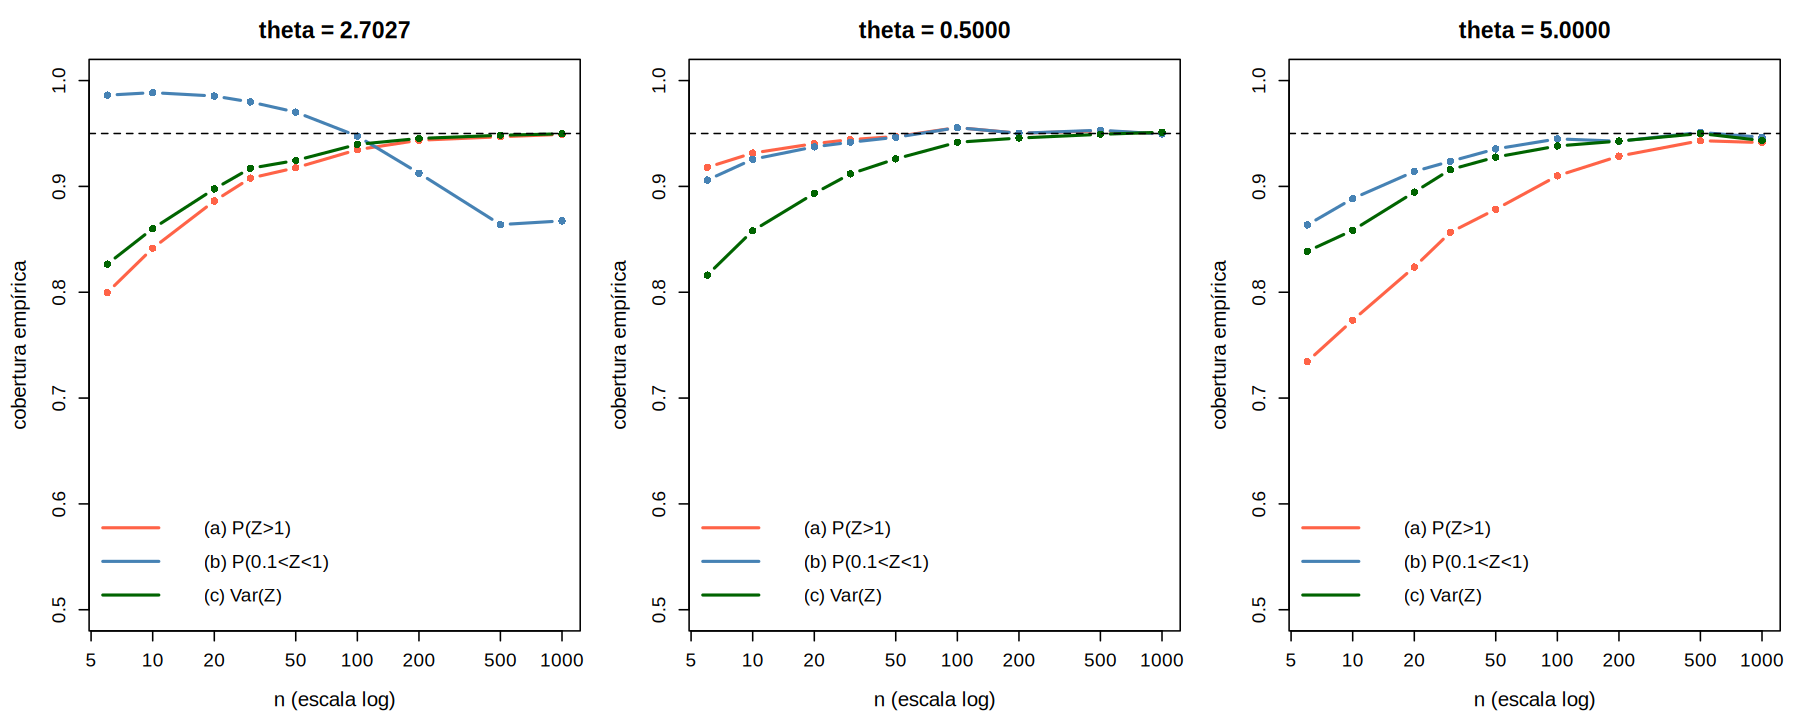

In [8]:
## ---- Exercício 2 (e): gráficos de cobertura x n ----
options(repr.plot.width = 12, repr.plot.height = 4.8, repr.plot.res = 150)
par(mfrow = c(1, 3), mar = c(4.5, 4.5, 3, 1), cex.lab = 1.25, cex.axis = 1.15,
    cex.main = 1.4)
cores <- c(a = "tomato", b = "steelblue", c = "darkgreen")
for (k in seq_along(res2e)) {
  m <- res2e[[k]]
  plot(ns, m[, "a"], type = "b", log = "x", ylim = c(0.5, 1), col = cores["a"],
       pch = 16, lwd = 2, xlab = "n (escala log)", ylab = "cobertura empírica",
       main = names(res2e)[k])
  lines(ns, m[, "b"], type = "b", col = cores["b"], pch = 16, lwd = 2)
  lines(ns, m[, "c"], type = "b", col = cores["c"], pch = 16, lwd = 2)
  abline(h = 0.95, lty = 2)
  legend("bottomright", bty = "n", lwd = 2, col = cores, cex = 1.15, inset = 0.02,
         seg.len = 1.5, x.intersp = 1.2, y.intersp = 2.2,
         legend = c("(a) P(Z>1)", "(b) P(0.1<Z<1)", "(c) Var(Z)"))
}

In [9]:
# Erro padrão de MC da cobertura: sqrt(0.95*0.05/MC) ~ 0.0022; +/- 0.01 ~ 4.5 EP.
tol <- 0.01
tab2e <- sapply(res2e, function(m) {
  apply(m[, c("a", "b", "c")], 2, function(cob) {
    # menor n a partir do qual a cobertura fica na tolerância para todo n maior
    dentro <- abs(cob - gama) <= tol
    idx <- which(rev(cumprod(rev(dentro))) == 1)
    if (length(idx) == 0) NA else ns[min(idx)]
  })
})
cat("Menor n da grade com |cobertura - 0.95| <= 0.01 para todo n maior:\n")
print(tab2e)

Menor n da grade com |cobertura - 0.95| <= 0.01 para todo n maior:
  theta = 2.7027 theta = 0.5000 theta = 5.0000
a            200             20            500
b             NA             30            100
c            200            100            200


**Resulatdos do item (e).**

Vemos que com $n=6$ **nenhum** dos três ICs delta tem cobertura próxima de 95%, confirmando que a aproximação
assintótica é inadequada para a amostra observada. Em detalhe, temos:

* **(a) $P(Z>1)=e^{-\theta}$.** Com $n=6$ a cobertura fica em torno de 80% para
  $\theta=\hat\theta_n$ e cai para cerca de 73% quando $\theta=5$ (quanto maior $\theta$, menor
  $g_a(\theta)$ e mais frequente o truncamento em 0). Para $\theta=0{,}5$ fica em torno de 92%.
  Vemos que a convergência para 95% é lenta, a cobertura só se estabiliza em $0{,}95\pm0{,}01$ a partir de
  $n\approx 200$ no cenário $\theta=\hat\theta_n$ (e $n\approx 500$ para $\theta=5$).
  Para resolver isso, podemos aumentar $n\ge 200$ para o valor de $\theta$ compatível com os dados. Quanto maior n, melhor.
* **(b) $P(0{,}1<Z<1)$.** No cenário $\theta=\hat\theta_n\approx2{,}70$, próximo de
  $\theta^*\approx2{,}56$ em que $g_b'=0$, a cobertura não converge para 95%, ela fica superior a 98%
  para $n$ pequeno (quando $\hat\theta_n$ ainda varia muito e raramente cai perto de $\theta^*$) e
  decresce para cerca de 86% quando $n\ge500$ (quando $\hat\theta_n$ concentra-se perto de
  $\theta^*$ e a variância estimada colapsa). Sabemos que o Teorema Delta exige $g'(\theta)\ne0$. Nenhum tamanho amostral irá onsertar o IC delta aqui, a saída
  é tomar a imagem por $g_b$ da região de confiança para $\theta$,
  $\{\theta : n(\hat\theta_n-\theta)^2/\hat\theta_n^2\le q_{\gamma,1}\}$ (um intervalo, pois $g_b$ é
  contínua), cuja cobertura é **no mínimo** a do IC de $\theta$, já que $\theta\in C_\gamma$ implica
  $g_b(\theta)\in g_b(C_\gamma)$ (≈ 95% já com $n=6$).
* **(c) $\mathrm{Var}(Z)=1/\theta^2$.** A cobertura é a mesma nos três cenários a menos do erro de
  Monte Carlo (como previsto, depende só de $\theta\bar Z_n$) e é a mais baixa dos três com $n=6$, pela forte assimetria à direita de $\bar Z_n^2$. Estabiliza em $0{,}95\pm0{,}01$ a
  partir de $n\approx 100$–$200$. Para melhorar, podemos aumentar $n\ge 200$ para o valor de $\theta$ compatível com os dados. Quanto maior n, melhor.

Em resumo, para os ICs aproximados do item (d) serem confiáveis com o método delta é preciso
$n$ da ordem de algumas centenas (≈ 200 para (a) e (c)); para (b) o método delta deve ser
substituído pela transformação da região de confiança de $\theta$.

## Exercício 3
> **Enunciado.** Seja $(Z_1,\dots,Z_n)$ uma amostra aleatória de $Z\sim N(\mu,\sigma^2)$,
> $\theta=(\mu,\sigma^2)\in(-\infty,\infty)\times(0,\infty)$.
>
> (a) Encontre o EMV para $g(\theta)=E_\theta(Z)$.
>
> (b) Encontre o EMV para $g(\theta)=P_\theta(Z<2)$.
>
> (c) Encontre o EMV para $g(\theta)=P_\theta(2{,}6<Z<4)$.
>
> (d) Encontre o EMV para $g(\theta)=\mathrm{Var}_\theta(Z)$.
>
> (e) Considere que os dados foram observados $(2{,}4;\ 2{,}7;\ 2{,}3;\ 2;\ 2{,}5;\ 2{,}6)$.
> Encontre as estimativas de MV nos itens acima.
>
> *Justifique todos os passos.*

$f_\theta(x) = (2\pi\sigma^2)^{-1/2}\exp\{-(x-\mu)^2/(2\sigma^2)\}$. Então

$$\ell(\mu,\sigma^2) = -\frac n2\ln(2\pi) - \frac n2\ln\sigma^2 - \frac1{2\sigma^2}\sum_{i=1}^n (z_i-\mu)^2.$$

Temos como condições:
$\dfrac{\partial\ell}{\partial\mu} = \dfrac1{\sigma^2}\sum(z_i-\mu) = 0 \iff \mu=\bar z_n$;
$\dfrac{\partial\ell}{\partial\sigma^2} = -\dfrac{n}{2\sigma^2}+\dfrac1{2\sigma^4}\sum(z_i-\mu)^2 = 0
\iff \sigma^2 = \dfrac1n\sum(z_i-\mu)^2$. Substituindo $\hat\mu=\bar z_n$:
$\hat\sigma^2 = \dfrac1n\sum_{i=1}^n(z_i-\bar z_n)^2$.

Para $\sigma^2$ fixo, $\ell$ é uma quadrática côncava em $\mu$ com máximo em
$\bar z_n$. A verossimilhança
$\ell_p(\sigma^2) = c - \frac n2\ln\sigma^2 - \frac{n\hat\sigma^2}{2\sigma^2}$ tende a $-\infty$
quando $\sigma^2\to0^+$ e quando $\sigma^2\to\infty$, tem único ponto crítico em $\hat\sigma^2$ e
$\ell_p''(\hat\sigma^2) = -n/(2\hat\sigma^4)<0$. Equivalentemente, a matriz hessiana em
$(\hat\mu,\hat\sigma^2)$ é $\mathrm{diag}(-n/\hat\sigma^2,\,-n/(2\hat\sigma^4))$ (o termo cruzado
$\sum(z_i-\hat\mu)/\hat\sigma^4$ é nulo), negativa definida. Logo
$\hat\theta_{MV} = \langle\bar Z_n,\ \tfrac1n\sum(Z_i-\bar Z_n)^2\rangle$.


Pela propriedade de invariância, agora com $\theta$ bidimensional e $g:\Theta\to\mathbb R$:

**(a) Encontre o EMV para $g(\theta)=E_\theta(Z)$.**<br>
 $g(\theta) = E_\theta(Z) = \mu$ $\Rightarrow$ $\hat g = \bar Z_n$.

**(b) Encontre o EMV para $g(\theta)=P_\theta(Z<2)$.**<br>
 $g(\theta) = P_\theta(Z<2) = \Phi\!\big((2-\mu)/\sigma\big)$ $\Rightarrow$
$\hat g = \Phi\!\big((2-\bar Z_n)/\hat\sigma\big)$, com $\hat\sigma=\sqrt{\hat\sigma^2}$.

**(c) Encontre o EMV para $g(\theta)=P_\theta(2{,}6<Z<4)$.** <br>
 $g(\theta) = P_\theta(2{,}6<Z<4) = \Phi\!\big((4-\mu)/\sigma\big)-\Phi\!\big((2{,}6-\mu)/\sigma\big)$
$\Rightarrow$ $\hat g = \Phi\!\big((4-\bar Z_n)/\hat\sigma\big)-\Phi\!\big((2{,}6-\bar Z_n)/\hat\sigma\big)$.

**(d) Encontre o EMV para $g(\theta)=\mathrm{Var}_\theta(Z)$.**<br>
 $g(\theta) = \mathrm{Var}_\theta(Z) = \sigma^2$ $\Rightarrow$ $\hat g = \hat\sigma^2$.

**(e) Considere que os dados foram observados $(2{,}4;\ 2{,}7;\ 2{,}3;\ 2;\ 2{,}5;\ 2{,}6)$.** <br>
Abaixo, caulculamos as estimativas de EV para o item e.


In [10]:
## ---- Exercício 3 (e): estimativas de MV ----
z3 <- c(2.4, 2.7, 2.3, 2, 2.5, 2.6)
n3 <- length(z3)
mu3.hat     <- mean(z3)
sigma23.hat <- mean((z3 - mu3.hat)^2)          # divide por n (EMV)
sigma3.hat  <- sqrt(sigma23.hat)

cat(sprintf("n = %d\n", n3))
cat(sprintf("EMV de mu       : %.6f\n", mu3.hat))
cat(sprintf("EMV de sigma^2  : %.6f   (compare: S^2_{n-1} = var(z) = %.6f)\n",
            sigma23.hat, var(z3)))
cat(sprintf("(a) EMV de E(Z)          : %.6f\n", mu3.hat))
cat(sprintf("(b) EMV de P(Z < 2)      : %.6f\n", pnorm((2 - mu3.hat) / sigma3.hat)))
cat(sprintf("(c) EMV de P(2.6 < Z < 4): %.6f\n",
            pnorm((4 - mu3.hat) / sigma3.hat) - pnorm((2.6 - mu3.hat) / sigma3.hat)))
cat(sprintf("(d) EMV de Var(Z)        : %.6f\n", sigma23.hat))

# Verificação numérica: maximização direta de l(mu, sigma^2) com optim()
# (parametrizamos sigma^2 = exp(par[2]) para manter sigma^2 > 0; o maximo e o mesmo)
negloglik3 <- function(par)
  -sum(dnorm(z3, mean = par[1], sd = sqrt(exp(par[2])), log = TRUE))
opt3 <- optim(c(mean(z3), log(var(z3))), negloglik3, method = "BFGS",
              control = list(reltol = 1e-14))
cat(sprintf("\noptim(): mu = %.6f, sigma^2 = %.6f  (confere com a forma fechada)\n",
            opt3$par[1], exp(opt3$par[2])))

n = 6
EMV de mu       : 2.416667
EMV de sigma^2  : 0.051389   (compare: S^2_{n-1} = var(z) = 0.061667)
(a) EMV de E(Z)          : 2.416667
(b) EMV de P(Z < 2)      : 0.033029
(c) EMV de P(2.6 < Z < 4): 0.209333
(d) EMV de Var(Z)        : 0.051389

optim(): mu = 2.416667, sigma^2 = 0.051389  (confere com a forma fechada)


## Exercício 4 — $f_\theta(x) = \theta x^{\theta-1}\,\mathbb I_{(0,1)}(x)$, $\theta\in(0,\infty)$

> **Enunciado.** Seja $(Z_1,\dots,Z_n)$ uma amostra aleatória de $Z\sim f_\theta$, $\theta\in(0,\infty)$,
> tal que a função densidade de probabilidade é dada por $f_\theta(x)=\theta x^{\theta-1}$, se
> $x\in(0,1)$, e $f_\theta(x)=0$, caso contrário.
>
> (a) Encontre o EMV para $g(\theta)=E_\theta(Z)$.
>
> (b) Encontre o EMV para $g(\theta)=P_\theta(Z>0{,}3)$.
>
> (c) Encontre o EMV para $g(\theta)=P_\theta(0<Z<0{,}1)$.
>
> (d) Encontre o EMV para $g(\theta)=\mathrm{Var}_\theta(Z)$.
>
> (e) Considere que os dados foram observados $(0{,}12;\ 0{,}50;\ 0{,}20;\ 0{,}23;\ 0{,}30;\ 0{,}11)$.
> Encontre as estimativas de MV para os itens acima.
>
> *Justifique todos os passos.*

Para $x_i\in(0,1)$,

$$L_{\mathbf z_n}(\theta) = \theta^n\prod_{i=1}^n x_i^{\theta-1},\qquad
\ell(\theta) = n\ln\theta + (\theta-1)\sum_{i=1}^n\ln x_i,$$
$$\ell'(\theta) = \frac n\theta + \sum_{i=1}^n\ln x_i = 0 \iff \hat\theta = -\frac{n}{\sum_{i=1}^n\ln x_i}.$$

Como $\ln x_i<0$, $\hat\theta>0\in\Theta$; e $\ell''(\theta)=-n/\theta^2<0$ para todo $\theta$, logo
$\hat\theta_{MV}(\mathbf Z_n) = -n/\sum\ln Z_i$ é o único máximo.

Para $k\ge0$,
$E_\theta(Z^k) = \int_0^1 x^k\,\theta x^{\theta-1}dx = \dfrac{\theta}{\theta+k}$. Logo:

**(a) Encontre o EMV para $g(\theta)=E_\theta(Z)$.**<br>
$g(\theta)=E_\theta(Z) = \dfrac{\theta}{\theta+1}$ $\Rightarrow$ $\hat g = \dfrac{\hat\theta}{\hat\theta+1}$.

**(b) Encontre o EMV para $g(\theta)=P_\theta(Z>0{,}3)$.** <br>

$g(\theta) = P_\theta(Z>0{,}3) = \int_{0{,}3}^1\theta x^{\theta-1}dx = 1-0{,}3^{\theta}$
  $\Rightarrow$ $\hat g = 1-0{,}3^{\hat\theta}$.

**(c) Encontre o EMV para $g(\theta)=P_\theta(0<Z<0{,}1)$.** <br>

$g(\theta) = P_\theta(0<Z<0{,}1) = 0{,}1^{\theta}$ $\Rightarrow$ $\hat g = 0{,}1^{\hat\theta}$.

**(d) Encontre o EMV para $g(\theta)=\mathrm{Var}_\theta(Z)$.**<br>

$g(\theta)=\mathrm{Var}_\theta(Z) = E_\theta(Z^2)-E_\theta(Z)^2$:
  $$\frac{\theta}{\theta+2}-\frac{\theta^2}{(\theta+1)^2}
  = \frac{\theta(\theta+1)^2-\theta^2(\theta+2)}{(\theta+1)^2(\theta+2)}
  = \frac{\theta}{(\theta+1)^2(\theta+2)}
  \quad\Rightarrow\quad \hat g = \frac{\hat\theta}{(\hat\theta+1)^2(\hat\theta+2)}.$$

Em todos os itens a justificativa é a propriedade de invariância.

**(e) Considere que os dados foram observados $(0{,}12;\ 0{,}50;\ 0{,}20;\ 0{,}23;\ 0{,}30;\ 0{,}11)$.** <br>
 Dados $\langle 0{,}12;\ 0{,}50;\ 0{,}20;\ 0{,}23;\ 0{,}30;\ 0{,}11\rangle$. Além da forma
fechada, obtemos $\hat\theta$ pelo método de Newton–Raphson com
$U_n(\theta) = n/\theta + \sum\ln x_i$ e $H_n(\theta) = -n/\theta^2$, partindo da estimativa de
momentos $\bar z_n = \theta/(\theta+1)\Rightarrow\theta^{(0)} = \bar z_n/(1-\bar z_n)$.

In [11]:
## ---- Exercício 4 (e): estimativas de MV ----
z4 <- c(0.12, 0.50, 0.20, 0.23, 0.30, 0.11)
n4 <- length(z4)
soma.log4  <- sum(log(z4))
theta4.hat <- -n4 / soma.log4

cat(sprintf("n = %d, soma de log(z) = %.6f\n", n4, soma.log4))
cat(sprintf("EMV de theta (forma fechada): %.6f\n", theta4.hat))
cat(sprintf("(a) EMV de E(Z) = theta/(theta+1)               : %.6f\n",
            theta4.hat / (theta4.hat + 1)))
cat(sprintf("(b) EMV de P(Z > 0.3) = 1 - 0.3^theta           : %.6f\n",
            1 - 0.3^theta4.hat))
cat(sprintf("(c) EMV de P(0 < Z < 0.1) = 0.1^theta           : %.6f\n",
            0.1^theta4.hat))
cat(sprintf("(d) EMV de Var(Z) = theta/((theta+1)^2(theta+2)): %.6f\n",
            theta4.hat / ((theta4.hat + 1)^2 * (theta4.hat + 2))))

# Confirmação com as funções de R para a Beta(theta, 1)
cat(sprintf("\nConferência via pbeta: P(Z>0.3) = %.6f, P(Z<0.1) = %.6f\n",
            1 - pbeta(0.3, theta4.hat, 1), pbeta(0.1, theta4.hat, 1)))

n = 6, soma de log(z) = -9.303772
EMV de theta (forma fechada): 0.644900
(a) EMV de E(Z) = theta/(theta+1)               : 0.392060
(b) EMV de P(Z > 0.3) = 1 - 0.3^theta           : 0.539960
(c) EMV de P(0 < Z < 0.1) = 0.1^theta           : 0.226517
(d) EMV de Var(Z) = theta/((theta+1)^2(theta+2)): 0.090116

Conferência via pbeta: P(Z>0.3) = 0.539960, P(Z<0.1) = 0.226517


Iteração 1: theta = 0.4828096713
Iteração 2: theta = 0.6041597579
Iteração 3: theta = 0.6423260573
Iteração 4: theta = 0.6448894318
Iteração 5: theta = 0.6448997024
Iteração 6: theta = 0.6448997026
Iteração 7: theta = 0.6448997026
Newton-Raphson: 0.6448997026   |   forma fechada: 0.6448997026
optimize():     0.6448997028


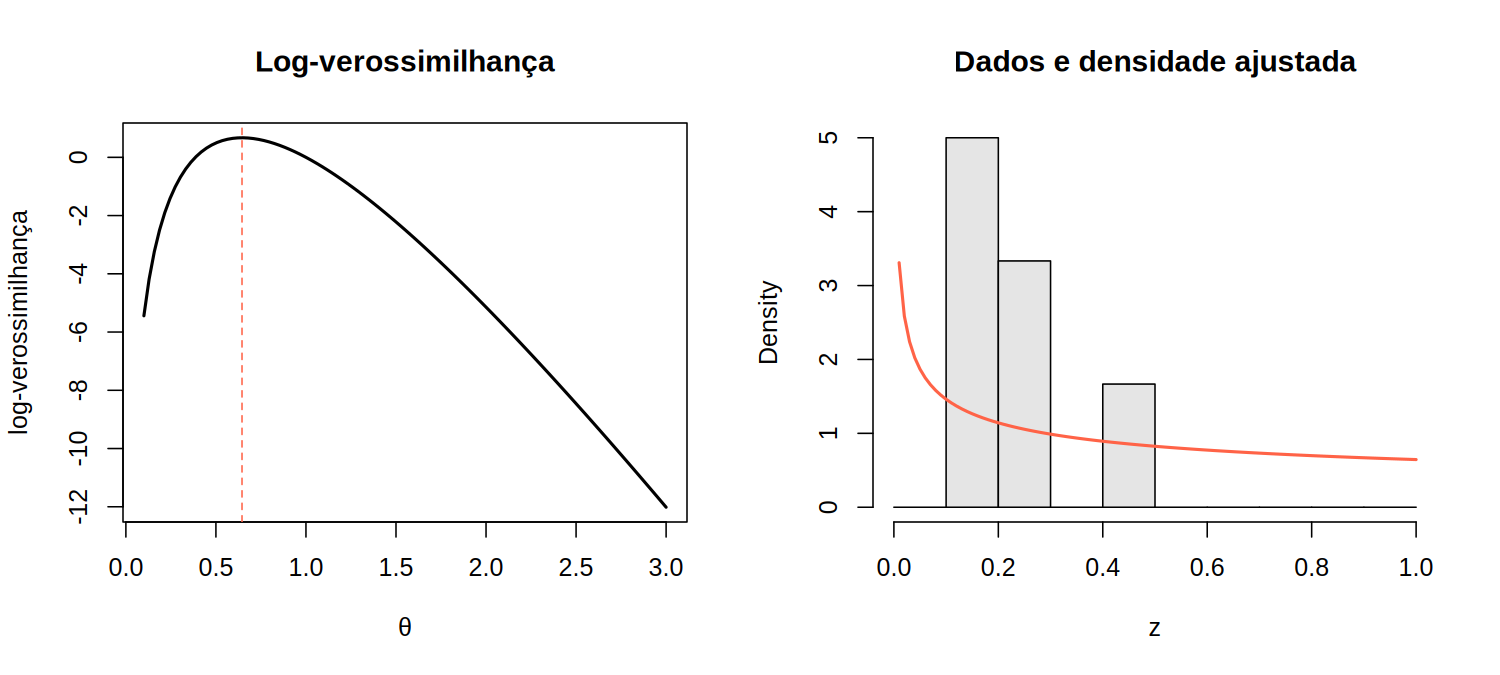

In [12]:
## ---- Exercício 4 (e): Newton-Raphson (Def. 2.5.1) e optimize() ----
U4 <- function(th) n4 / th + soma.log4          # função escore
H4 <- function(th) -n4 / th^2                   # derivada do escore

theta.nr <- numeric()
theta.nr[1] <- mean(z4) / (1 - mean(z4))
erro <- 1; j <- 0
while (erro > 1e-10) {
  j <- j + 1
  theta.nr[j + 1] <- theta.nr[j] - U4(theta.nr[j]) / H4(theta.nr[j])
  erro <- abs(theta.nr[j + 1] - theta.nr[j])
  cat(sprintf("Iteração %d: theta = %.10f\n", j, theta.nr[j + 1]))
}
cat(sprintf("Newton-Raphson: %.10f   |   forma fechada: %.10f\n",
            theta.nr[j + 1], theta4.hat))

loglik4 <- function(th) n4 * log(th) + (th - 1) * soma.log4
opt4 <- optimize(loglik4, interval = c(1e-6, 50), maximum = TRUE, tol = 1e-12)
cat(sprintf("optimize():     %.10f\n", opt4$maximum))

# Verossimilhança e densidade ajustada
options(repr.plot.width = 10, repr.plot.height = 4.5)
par(mfrow = c(1, 2))
curve(loglik4, 0.1, 3, lwd = 2, xlab = expression(theta),
      ylab = "log-verossimilhança", main = "Log-verossimilhança")
abline(v = theta4.hat, col = "tomato", lty = 2)
hist(z4, probability = TRUE, breaks = seq(0, 1, 0.1), col = "grey90", xlab = "z",
     main = "Dados e densidade ajustada")
curve(dbeta(x, theta4.hat, 1), add = TRUE, col = "tomato", lwd = 2)